In [1]:
    ################# Deep Neural Networks Regression-Kriging using PyTorch and Spatial Radial Basis Function (SBF) #############################

In [31]:
# If you receive the message "The kernel ... appears to have died. It will restart automatically."
# OpenMP Runtime Conflict: If you see the crash during imports like Scikit-Learn or PyTorch, set this environment variable at the very top of your notebook:
# Type the following codes

import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [32]:
########## 1. Installing and Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)


In [33]:
# 2. Loading the dataset
data = pd.read_csv('E:/VData/SData/Wells4.csv')

In [34]:
seed = 42

In [35]:
data.head()

,x_coord,y_coord,Depth,pH,SO4,NO3,T
0,17.74,15.57,259.0,7.00,39.0,9.0,27.0
1,17.48,15.82,220.0,6.60,17.0,12.0,34.7
2,17.48,15.83,220.0,6.00,925.0,5.0,27.0
3,17.39,15.37,286.0,7.00,3300.0,1.0,29.0
4,17.35,13.80,47.0,7.45,13.0,0.2,26.5


In [36]:
data.describe()

,x_coord,y_coord,Depth,pH,SO4,NO3,T
count,1311.000000,1311.000000,1311.000000,1311.000000,1311.000000,1311.000000,1311.000000
mean,15.499214,13.761732,49.371823,7.047918,49.873158,6.258383,28.451777
std,0.536874,0.508679,19.132128,0.618476,146.064968,15.023649,2.827740
min,13.930000,12.270000,15.400000,4.000000,0.000000,0.000000,10.000000
25%,15.230000,13.440000,38.000000,6.730000,9.000000,1.300000,27.000000
50%,15.480000,13.780000,48.000000,7.000000,18.000000,2.800000,29.000000
75%,15.730000,14.125000,56.000000,7.375000,35.000000,7.000000,30.000000
max,17.740000,15.830000,286.000000,10.800000,3300.000000,278.000000,35.100000


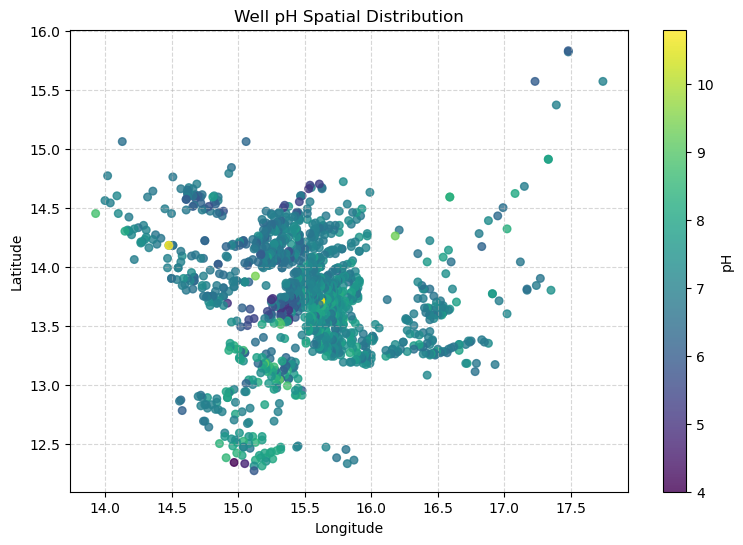

In [37]:
###### 3. Exploratory Data Visualization
plt.figure(figsize = (9, 6))
scatter = plt.scatter(data['x_coord'], data['y_coord'], c = data['pH'], cmap = 'viridis', alpha = 0.8, s = 30)
plt.colorbar(scatter, label = 'pH')
plt.title('Well pH Spatial Distribution')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True, linestyle = '--', alpha = 0.5)
plt.show()

In [8]:
# 4. Spatial Basis Function Expansion (Deep Kriging Core)

In [38]:
# a. Defining the SBF class
class SpatialRadialBasisFunctions:
    def __init__(self, num_knots = 50, bandwidth = 0.5):
        self.num_knots = num_knots
        self.bandwidth = bandwidth
        self.knots = None
        
    def fit(self, coords):
        # Sampling knots uniformly from coordinate space boundaries
        min_coords = coords.min(axis=0)
        max_coords = coords.max(axis=0)
        
        # Grid placement or random sampling across domain
        grid_lat = np.linspace(min_coords[0], max_coords[0], int(np.sqrt(self.num_knots)))
        grid_lon = np.linspace(min_coords[1], max_coords[1], int(np.sqrt(self.num_knots)))
        mesh_lat, mesh_lon = np.meshgrid(grid_lat, grid_lon)
        self.knots = np.column_stack([mesh_lat.ravel(), mesh_lon.ravel()])
        
    def transform(self, coords):
        # Computing the pairwise Euclidean distance between coordinates and knots
        dists = np.linalg.norm(coords[:, np.newaxis, :] - self.knots[np.newaxis, :, :], axis=2)
        # Applying Gaussian kernel function
        rbf_features = np.exp(- (dists ** 2) / (2 * (self.bandwidth ** 2)))
        return rbf_features

In [39]:
# b. Extracting the coordinates and target magnitude
coords = data[['y_coord', 'x_coord']].values
target = data['pH'].values.reshape(-1, 1)

In [42]:
# c. Fitting and transforming spatial coordinates into RBF basis embeddings
rbf = SpatialRadialBasisFunctions(num_knots = 64, bandwidth = 1.5)
rbf.fit(coords)
rbf_features = rbf.transform(coords)

In [43]:
print(f"Original spatial dim: {coords.shape[1]} -> RBF expanded dim: {rbf_features.shape[1]}")

Original spatial dim: 2 -> RBF expanded dim: 64


In [13]:
############# 5. Data Preprocessing and Train-Test Split

In [44]:
# a. Combining raw coordinates and spatial basis embeddings
X = np.hstack((coords, rbf_features))
y = target

In [45]:
# b. Splitting the dataset into training and testing datasets
X_train, X_test, y_train, y_test, coords_train, coords_test = train_test_split(X, y, coords, test_size = 0.3, random_state = 42)

In [46]:
# c. Scaling features and targets
# Initializing the scalers
scaler_X = StandardScaler()
scaler_y = StandardScaler()

# Scaling the features
X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

# Scaling the target
y_train_scaled = scaler_y.fit_transform(y_train)
y_test_scaled = scaler_y.transform(y_test)

In [47]:
# d. Converting to PyTorch tensors
train_dataset = TensorDataset(
    torch.tensor(X_train_scaled, dtype = torch.float32),
    torch.tensor(y_train_scaled, dtype = torch.float32)
)
test_dataset = TensorDataset(
    torch.tensor(X_test_scaled, dtype = torch.float32),
    torch.tensor(y_test_scaled, dtype = torch.float32)
)

train_loader = DataLoader(train_dataset, batch_size = 16, shuffle = True)
test_loader = DataLoader(test_dataset, batch_size = 16, shuffle = True)


In [48]:
############## 6. Defining Deep Kriging Neural Network Architecture
class DeepKrigingNN(nn.Module):
    def __init__(self, input_dim):
        super(DeepKrigingNN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.1),
            
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            
            nn.Linear(64, 32),
            nn.ReLU(),
            
            nn.Linear(32, 1)
        )
        
    def forward(self, x):
        return self.net(x)

model = DeepKrigingNN(input_dim = X_train.shape[1])
criterion = nn.MSELoss()
optimizer = optim.RMSprop(model.parameters(), lr = 0.003, weight_decay = 1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode = 'min', factor = 0.5, patience = 15)


Epoch 1/150 - Loss: 0.95
Epoch 25/150 - Loss: 0.81
Epoch 50/150 - Loss: 0.81
Epoch 75/150 - Loss: 0.79
Epoch 100/150 - Loss: 0.77
Epoch 125/150 - Loss: 0.74
Epoch 150/150 - Loss: 0.73


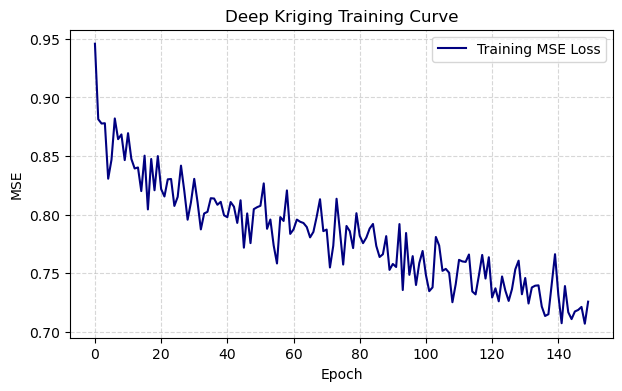

In [49]:
########## 7. Model Training Loop
# Training loss
epochs = 150
train_losses = []

model.train()
for epoch in range(epochs):
    epoch_loss = 0.0
    for batch_x, batch_y in train_loader:
        optimizer.zero_grad()
        predictions = model(batch_x)
        loss = criterion(predictions, batch_y)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * batch_x.size(0)
        
    total_epoch_loss = epoch_loss / len(train_loader.dataset)
    train_losses.append(total_epoch_loss)
    scheduler.step(total_epoch_loss)
    
    if (epoch + 1) % 25 == 0 or epoch == 0:
        print(f"Epoch {epoch+1}/{epochs} - Loss: {total_epoch_loss:.2f}")

plt.figure(figsize=(7, 4))
plt.plot(train_losses, label = 'Training MSE Loss', color = 'navy')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.title('Deep Kriging Training Curve')
plt.legend()
plt.grid(True, linestyle = '--', alpha = 0.5)
plt.show()


Epoch 1/150 - Loss: 0.64
Epoch 25/150 - Loss: 0.61
Epoch 50/150 - Loss: 0.58
Epoch 75/150 - Loss: 0.57
Epoch 100/150 - Loss: 0.57
Epoch 125/150 - Loss: 0.56
Epoch 150/150 - Loss: 0.55


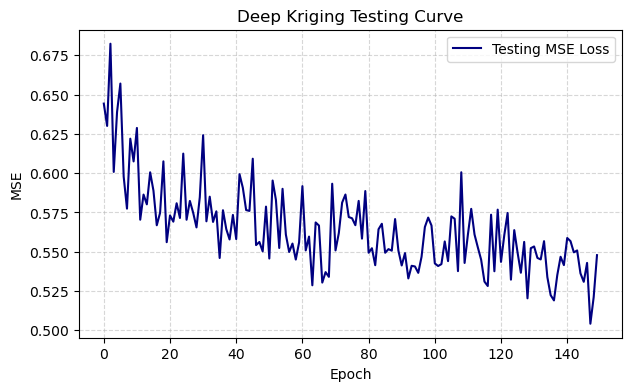

In [50]:
# Testing loss
epochs = 150
test_losses = []

model.train()
for epoch in range(epochs):
    epoch_loss = 0.0
    for batch_x, batch_y in test_loader:
        optimizer.zero_grad()
        predictions = model(batch_x)
        loss = criterion(predictions, batch_y)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * batch_x.size(0)
        
    total_epoch_loss = epoch_loss / len(test_loader.dataset)
    test_losses.append(total_epoch_loss)
    scheduler.step(total_epoch_loss)
    
    if (epoch + 1) % 25 == 0 or epoch == 0:
        print(f"Epoch {epoch+1}/{epochs} - Loss: {total_epoch_loss:.2f}")

plt.figure(figsize=(7, 4))
plt.plot(test_losses, label = 'Testing MSE Loss', color = 'navy')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.title('Deep Kriging Testing Curve')
plt.legend()
plt.grid(True, linestyle = '--', alpha = 0.5)
plt.show()

In [21]:
########### 8. Model Evaluation

In [51]:
# Training metrics
model.eval()
with torch.no_grad():
    X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
    preds_scaled = model(X_train_tensor).numpy()

# Inverse transform to original scale
preds_ph = scaler_y.inverse_transform(preds_scaled)

r2 = r2_score(y_train, preds_ph)
rmse = np.sqrt(mean_squared_error(y_train, preds_ph))
mae = mean_absolute_error(y_train, preds_ph)


print(f"Training R² Score: {r2:.2f}")
print(f"Training RMSE: {rmse:.2f}")
print(f"Training MAE: {mae:.2f}")



Training R² Score: 0.23
Training RMSE: 0.56
Training MAE: 0.39


In [52]:
## Testing metrics
model.eval()
with torch.no_grad():
    X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
    preds_scaled = model(X_test_tensor).numpy()

# Inverse transform to original scale
preds_ph_ts = scaler_y.inverse_transform(preds_scaled)

r2 = r2_score(y_test, preds_ph_ts)
rmse = np.sqrt(mean_squared_error(y_test, preds_ph_ts))
mae = mean_absolute_error(y_test, preds_ph_ts)

print(f"Testing R² Score: {r2:.2f}")
print(f"Testing RMSE: {rmse:.2f}")
print(f"Testing MAE: {mae:.2f}")

Testing R² Score: 0.37
Testing RMSE: 0.45
Testing MAE: 0.33


In [23]:
########## 9. Spatial Interpolation Grid Generation

In [53]:
# a. Constructing dense spatial grid
lat_grid = np.linspace(data['y_coord'].min() - 0.5, data['y_coord'].max() + 0.5, 100)
lon_grid = np.linspace(data['x_coord'].min() - 0.5, data['x_coord'].max() + 0.5, 100)
mesh_lon, mesh_lat = np.meshgrid(lon_grid, lat_grid)

grid_coords = np.column_stack([mesh_lat.ravel(), mesh_lon.ravel()])


In [54]:
# b. Applying the Spatial Basis Expansion
grid_rbf_features = rbf.transform(grid_coords)
grid_X = np.hstack((grid_coords, grid_rbf_features))

In [55]:
# c. Scaling
grid_X_scaled = scaler_X.transform(grid_X)
grid_tensor = torch.tensor(grid_X_scaled, dtype = torch.float32)

In [57]:
# d. Predicting
model.eval()
with torch.no_grad():
    grid_preds_scaled = model(grid_tensor).numpy()
grid_preds = scaler_y.inverse_transform(grid_preds_scaled).reshape(mesh_lat.shape)

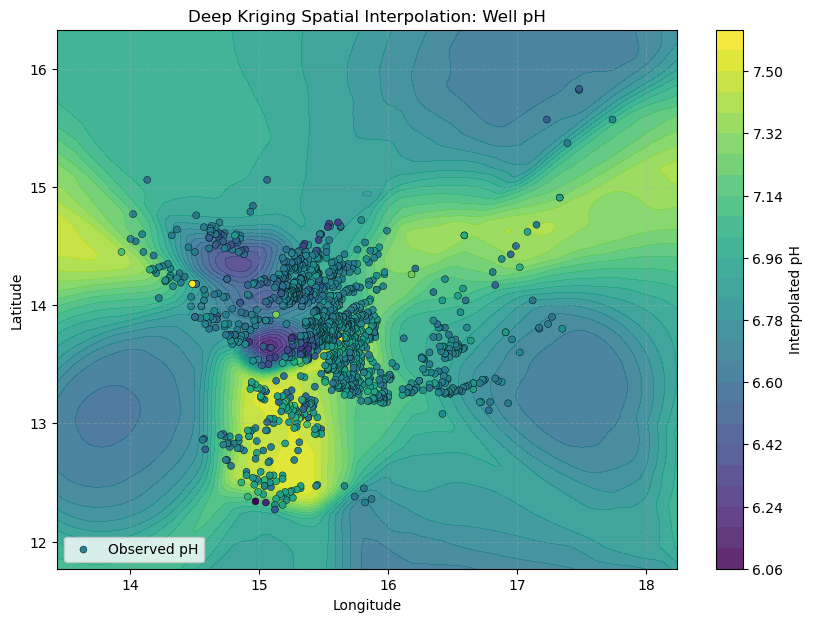

In [58]:
# Plotting the Spatial Interpolation Surface
plt.figure(figsize = (10, 7))
contour = plt.contourf(mesh_lon, mesh_lat, grid_preds, levels = 25, cmap = 'viridis', alpha = 0.85)
plt.colorbar(contour, label = 'Interpolated pH')

# Overlay actual earthquake observations
plt.scatter(data['x_coord'], data['y_coord'], c = data['pH'], cmap = 'viridis', edgecolors = 'k', linewidth = 0.3, s = 25, label = 'Observed pH')

plt.title('Deep Kriging Spatial Interpolation: Well pH')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend(loc = 'lower left')
plt.grid(True, linestyle = '--', alpha = 0.3)
plt.show()


In [29]:
############# 10. Empirical Variogram Plot

<>:35: SyntaxWarning: invalid escape sequence '\g'
<>:35: SyntaxWarning: invalid escape sequence '\g'
C:\Users\Djimadoumngar\AppData\Local\Temp\ipykernel_11316\539384188.py:35: SyntaxWarning: invalid escape sequence '\g'
  plt.ylabel('Semi-variance $\gamma(h)$')


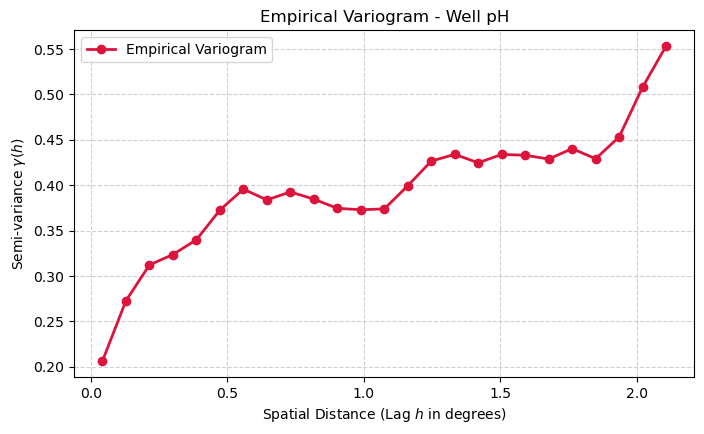

In [59]:
# Establishing the spatial correlation by calculating and plotting an Empirical Semi-Variogram before running Deep Kriging.
from scipy.spatial.distance import pdist, squareform
def compute_empirical_variogram(coords, values, n_lags = 20, max_dist = None):
    # Pairwise spatial distances
    dist_matrix = squareform(pdist(coords))
    
    # Pairwise squared differences of values
    val_diff_matrix = 0.5 * (values[:, None] - values[None, :]) ** 2
    
    if max_dist is None:
        max_dist = dist_matrix.max() / 2.0  # Common spatial rule of thumb
        
    bins = np.linspace(0, max_dist, n_lags + 1)
    bin_centers = (bins[:-1] + bins[1:]) / 2
    gamma = []
    
    for i in range(n_lags):
        mask = (dist_matrix >= bins[i]) & (dist_matrix < bins[i+1])
        if np.sum(mask) > 0:
            gamma.append(np.mean(val_diff_matrix[mask]))
        else:
            gamma.append(np.nan)
            
    return bin_centers, np.array(gamma)

# Extract coordinates and target variable
coords = data[['y_coord', 'x_coord']].values
target = data['pH'].values

lags, gamma = compute_empirical_variogram(coords, target, n_lags = 25)

plt.figure(figsize=(8, 4.5))
plt.plot(lags, gamma, 'o-', color = 'crimson', linewidth=2, label = 'Empirical Variogram')
plt.xlabel('Spatial Distance (Lag $h$ in degrees)')
plt.ylabel('Semi-variance $\gamma(h)$')
plt.title('Empirical Variogram - Well pH')
plt.grid(True, linestyle = '--', alpha = 0.6)
plt.legend()
plt.show()
